In [14]:
import numpy as np
import matplotlib.pyplot as plt

def plot_environmental_heatmap(accuracies, temp_range, vdd_range, puf_name, attack_name):
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(accuracies, cmap="viridis", interpolation='nearest', origin='lower')
    
    cbar = ax.figure.colorbar(im, ax=ax)
    cbar.ax.set_ylabel("Model Accuracy", rotation=-90, va="bottom")

    ax.set_xticks(np.arange(len(vdd_range)))
    ax.set_yticks(np.arange(len(temp_range)))
    ax.set_xticklabels(vdd_range)
    ax.set_yticklabels(temp_range)
    ax.set_xlabel("Vdd (V)")
    ax.set_ylabel("Temperature (°C)")

    # Annotate with accuracy values
    #for r in range(len(temp_range)):
    #    for c in range(len(vdd_range)):
            #ax.text(c, r, f"{accuracies[r, c]:.3f}", ha="center", va="center", 
             #       color="w" if accuracies[r, c] < 0.8 else "black")

    ax.set_title(f"{attack_name} Accuracy vs. Environment\nTarget: {puf_name}")
    plt.tight_layout()
    plt.show()

Epoch 1/50
50/50 [==============================] - 1s 12ms/step - loss: 0.7191 - accuracy: 0.5584 - val_loss: 0.6320 - val_accuracy: 0.6340
Epoch 2/50
50/50 [==============================] - 0s 5ms/step - loss: 0.5439 - accuracy: 0.7315 - val_loss: 0.4945 - val_accuracy: 0.7740
Epoch 3/50
50/50 [==============================] - 0s 5ms/step - loss: 0.4412 - accuracy: 0.8311 - val_loss: 0.4108 - val_accuracy: 0.8640
Epoch 4/50
50/50 [==============================] - 0s 4ms/step - loss: 0.3765 - accuracy: 0.8836 - val_loss: 0.3551 - val_accuracy: 0.9100
Epoch 5/50
50/50 [==============================] - 0s 5ms/step - loss: 0.3322 - accuracy: 0.9124 - val_loss: 0.3165 - val_accuracy: 0.9160
Epoch 6/50
50/50 [==============================] - 0s 4ms/step - loss: 0.2999 - accuracy: 0.9308 - val_loss: 0.2880 - val_accuracy: 0.9300
Epoch 7/50
50/50 [==============================] - 0s 3ms/step - loss: 0.2752 - accuracy: 0.9420 - val_loss: 0.2655 - val_accuracy: 0.9480
Epoch 8/50
50/50 [=

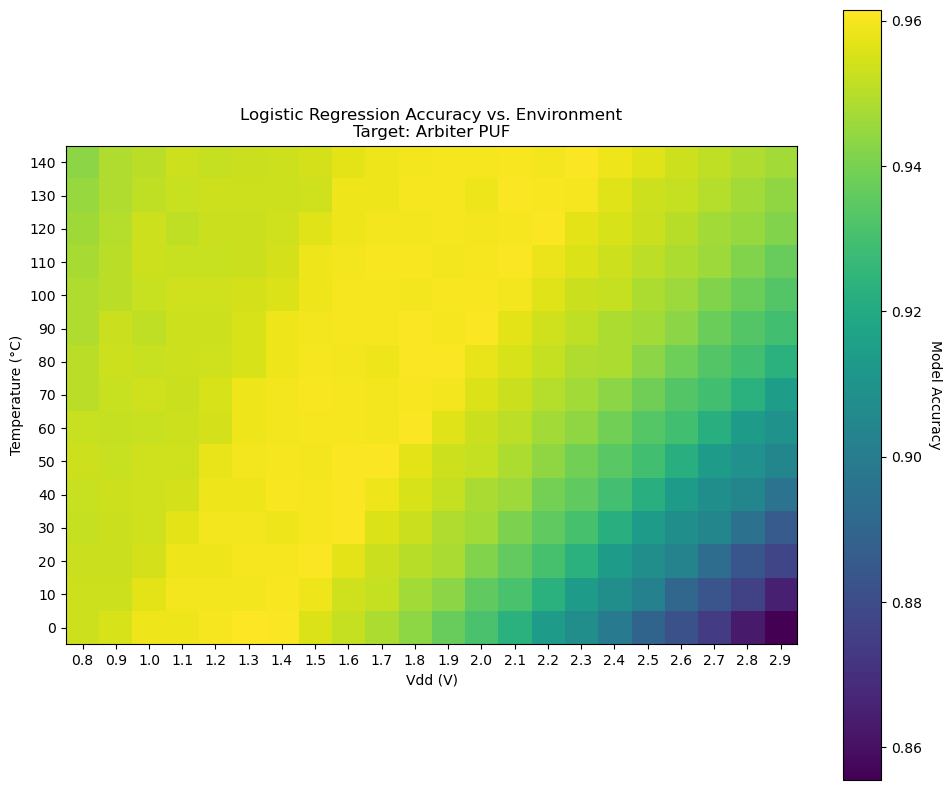

In [22]:
from pypuf.simulation import ArbiterPUF
from pypuf.io import ChallengeResponseSet
from pypuf.attack import LRAttack2021
from pypuf.metrics import similarity

# 1. Setup
n_bits, puf_seed = 64, 123
nom_temp, nom_vdd = 25.0, 1.2
n_train, n_test = 50000, 2000
temp_range = np.arange(0, 150, 10)
vdd_range = np.round(np.arange(0.8, 3.00, 0.1), 2)

# 2. Train at Nominal (Golden Point)
p_nom = ArbiterPUF(n=n_bits, seed=puf_seed, noisiness=0.05, temperature=nom_temp, vdd=nom_vdd)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=n_train, seed= puf_seed)
# LR: (crps, seed, k, bs, lr, epochs) [cite: 39, 46]
model = LRAttack2021(train_crps, 42, 1, 1000, 1e-3, 50).fit() #[cite: 58]
model.temperature, model.vdd = nom_temp, nom_vdd


# 3. Environmental Sweep
acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        p_eval = ArbiterPUF(n=n_bits, seed=puf_seed, temperature=t, vdd=v)
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0] #[cite: 358]

plot_environmental_heatmap(acc_grid, temp_range, vdd_range, "Arbiter PUF", "Logistic Regression")

Epoch 1/50
387/387 [==============================] - 3s 4ms/step - loss: 0.1025 - accuracy: 0.9589 - val_loss: 0.0595 - val_accuracy: 0.9700
Epoch 2/50
387/387 [==============================] - 1s 3ms/step - loss: 0.0515 - accuracy: 0.9777 - val_loss: 0.0656 - val_accuracy: 0.9720
Epoch 3/50
387/387 [==============================] - 1s 3ms/step - loss: 0.0485 - accuracy: 0.9788 - val_loss: 0.0692 - val_accuracy: 0.9720
Epoch 4/50
387/387 [==============================] - 1s 3ms/step - loss: 0.0454 - accuracy: 0.9806 - val_loss: 0.0495 - val_accuracy: 0.9760
Epoch 5/50
387/387 [==============================] - 1s 3ms/step - loss: 0.0443 - accuracy: 0.9806 - val_loss: 0.0471 - val_accuracy: 0.9780
Epoch 6/50
387/387 [==============================] - 1s 3ms/step - loss: 0.0426 - accuracy: 0.9817 - val_loss: 0.0575 - val_accuracy: 0.9680
Epoch 7/50
387/387 [==============================] - 1s 3ms/step - loss: 0.0420 - accuracy: 0.9815 - val_loss: 0.0540 - val_accuracy: 0.9700
Epoch 

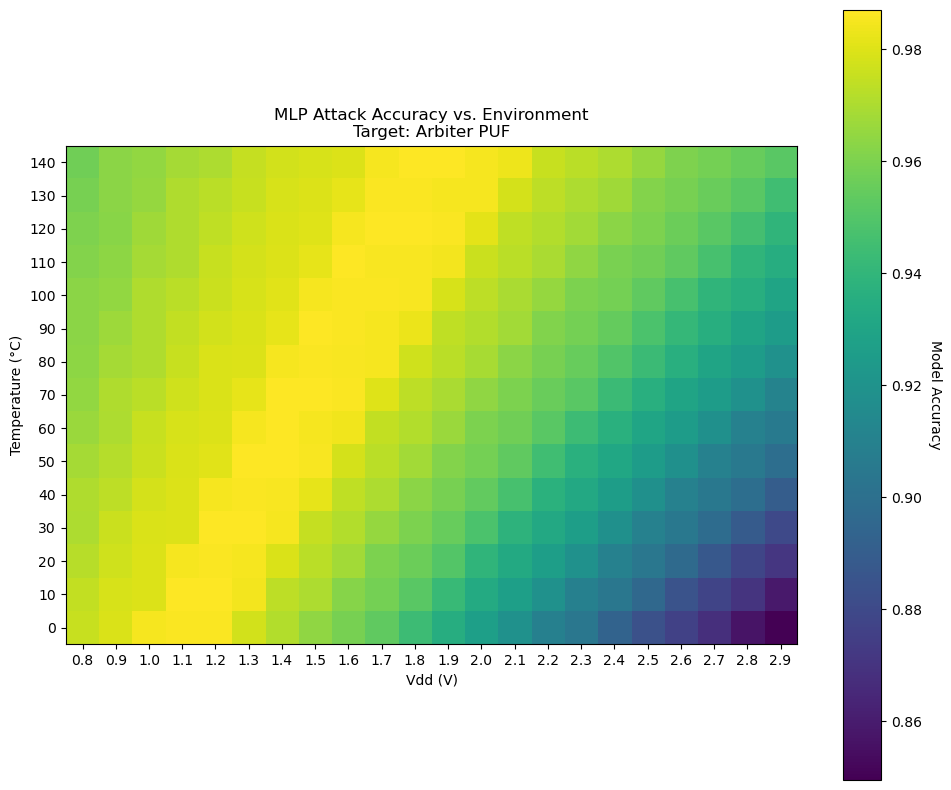

In [23]:
from pypuf.simulation import ArbiterPUF
from pypuf.io import ChallengeResponseSet
from pypuf.attack import MLPAttack2021
from pypuf.metrics import similarity

# 1. Setup (Inherited from your previous configuration)
n_bits, puf_seed = 64, 123
nom_temp, nom_vdd = 25.0, 1.2
n_train, n_test = 50000, 2000
temp_range = np.arange(0, 150, 10)
vdd_range = np.round(np.arange(0.8, 3.00, 0.1), 2)

# 2. Train at Nominal (Golden Point)
p_nom = ArbiterPUF(n=n_bits, seed=puf_seed, noisiness=0.05, temperature=nom_temp, vdd=nom_vdd)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=n_train, seed=puf_seed)

# MLP Attack Configuration:
# Arguments: (crps, seed, net, epochs, lr, bs, early_stop)
# net=[n_bits, n_bits] defines two hidden layers matching the challenge length
model = MLPAttack2021(
    train_crps, 
    seed=42, 
    net=[n_bits, n_bits], 
    epochs=50, 
    lr=1e-3, 
    bs=128, 
    early_stop=0.01
).fit()

# Assign nominal conditions for physics-aware evaluation
model.temperature, model.vdd = nom_temp, nom_vdd

# 3. Environmental Sweep
acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        # Create target instance with shifted environmental parameters
        p_eval = ArbiterPUF(n=n_bits, seed=puf_seed, temperature=t, vdd=v)
        
        # similarity() compares the fixed MLP model against the shifted device
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0]

# 4. Visualization
plot_environmental_heatmap(acc_grid, temp_range, vdd_range, "Arbiter PUF", "MLP Attack")

Epoch 1/50
774/774 [==============================] - 5s 4ms/step - loss: 0.6996 - accuracy: 0.4990 - val_loss: 0.6979 - val_accuracy: 0.4990
Epoch 2/50
774/774 [==============================] - 3s 4ms/step - loss: 0.6953 - accuracy: 0.5105 - val_loss: 0.6908 - val_accuracy: 0.5220
Epoch 3/50
774/774 [==============================] - 3s 4ms/step - loss: 0.6939 - accuracy: 0.5156 - val_loss: 0.6944 - val_accuracy: 0.5010
Epoch 4/50
774/774 [==============================] - 3s 4ms/step - loss: 0.6922 - accuracy: 0.5231 - val_loss: 0.6918 - val_accuracy: 0.5140
Epoch 5/50
774/774 [==============================] - 4s 5ms/step - loss: 0.6903 - accuracy: 0.5321 - val_loss: 0.6912 - val_accuracy: 0.5360
Epoch 6/50
774/774 [==============================] - 3s 4ms/step - loss: 0.6851 - accuracy: 0.5527 - val_loss: 0.6846 - val_accuracy: 0.5700
Epoch 7/50
774/774 [==============================] - 3s 4ms/step - loss: 0.6698 - accuracy: 0.5883 - val_loss: 0.6650 - val_accuracy: 0.5930
Epoch 

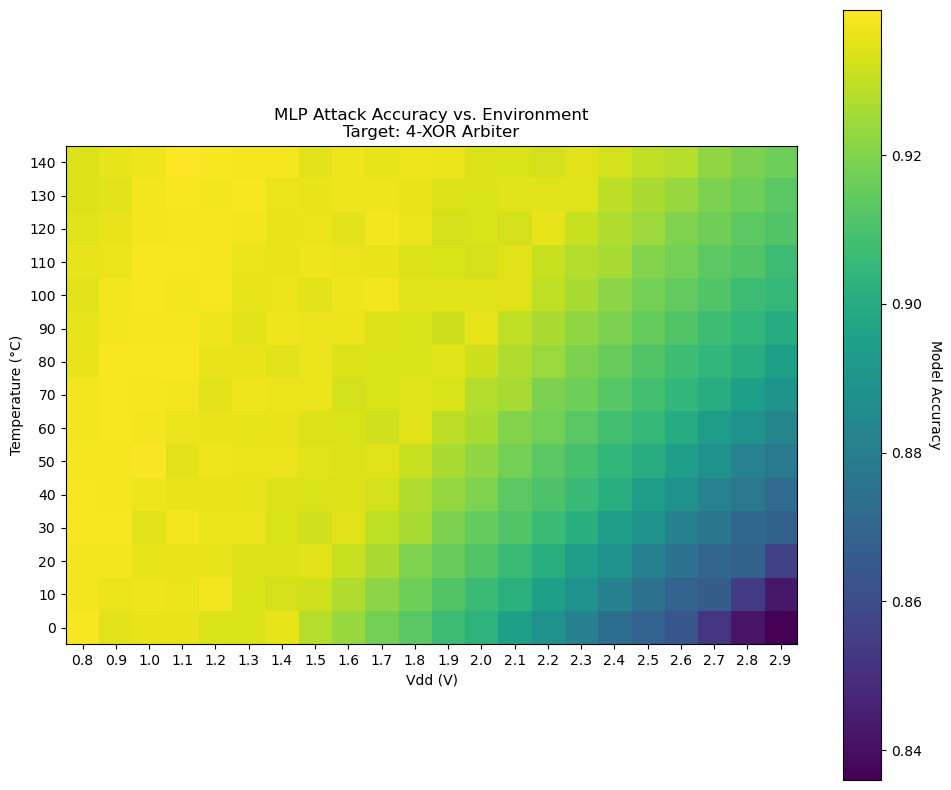

In [17]:
from pypuf.simulation import XORArbiterPUF
from pypuf.attack import MLPAttack2021

k = 4
p_nom = XORArbiterPUF(n=n_bits, k=k, seed=puf_seed, noisiness=0.05, temperature=nom_temp, vdd=nom_vdd) #[cite: 13, 161]
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=100000, seed=puf_seed) # Increased data for XOR

# MLP: (crps, seed, net, epochs, lr, bs, early_stop) [cite: 204, 209]
model = MLPAttack2021(train_crps, 42, [n_bits, n_bits], 50, 1e-3, 128, 0.01).fit() #[cite: 171]
model.temperature, model.vdd = nom_temp, nom_vdd

acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        p_eval = XORArbiterPUF(n=n_bits, k=k, seed=puf_seed, temperature=t, vdd=v)
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0] #3[cite: 182]

plot_environmental_heatmap(acc_grid, temp_range, vdd_range, f"{k}-XOR Arbiter", "MLP Attack")

Epoch 1/50
387/387 [==============================] - 2s 3ms/step - loss: 0.3596 - accuracy: 0.8312 - val_loss: 0.3497 - val_accuracy: 0.8500
Epoch 2/50
387/387 [==============================] - 1s 3ms/step - loss: 0.3417 - accuracy: 0.8396 - val_loss: 0.3395 - val_accuracy: 0.8480
Epoch 3/50
387/387 [==============================] - 1s 3ms/step - loss: 0.3300 - accuracy: 0.8466 - val_loss: 0.3335 - val_accuracy: 0.8600
Epoch 4/50
387/387 [==============================] - 1s 3ms/step - loss: 0.3050 - accuracy: 0.8600 - val_loss: 0.2934 - val_accuracy: 0.8780
Epoch 5/50
387/387 [==============================] - 1s 2ms/step - loss: 0.2676 - accuracy: 0.8794 - val_loss: 0.2544 - val_accuracy: 0.8720
Epoch 6/50
387/387 [==============================] - 1s 3ms/step - loss: 0.2275 - accuracy: 0.9002 - val_loss: 0.2161 - val_accuracy: 0.9040
Epoch 7/50
387/387 [==============================] - 1s 2ms/step - loss: 0.1900 - accuracy: 0.9208 - val_loss: 0.1762 - val_accuracy: 0.9380
Epoch 

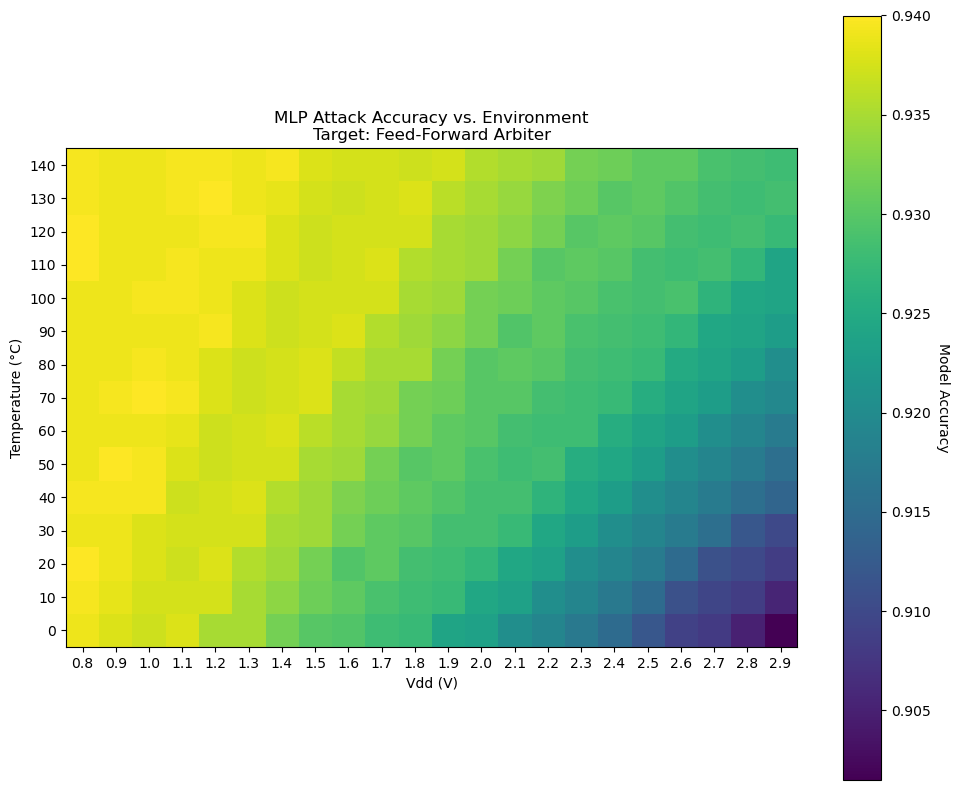

In [18]:
from pypuf.simulation import FeedForwardArbiterPUF

# Define FF bit indices: [(trigger_index, target_index), ...]
p_nom = FeedForwardArbiterPUF(n=n_bits, ff=[(10, 20), (30, 40)], seed=puf_seed, temperature=nom_temp, vdd=nom_vdd)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=n_train, seed=puf_seed)

model = MLPAttack2021(train_crps, 42, [n_bits, n_bits], 50, 1e-3, 128, 0.01).fit()
model.temperature, model.vdd = nom_temp, nom_vdd

acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        p_eval = FeedForwardArbiterPUF(n=n_bits, ff=[(10, 20), (30, 40)], seed=puf_seed, temperature=t, vdd=v)
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0]

plot_environmental_heatmap(acc_grid, temp_range, vdd_range, "Feed-Forward Arbiter", "MLP Attack")

Epoch 1/50
387/387 [==============================] - 2s 3ms/step - loss: 0.7018 - accuracy: 0.5013 - val_loss: 0.6943 - val_accuracy: 0.5160
Epoch 2/50
387/387 [==============================] - 2s 4ms/step - loss: 0.6953 - accuracy: 0.5081 - val_loss: 0.6945 - val_accuracy: 0.4920
Epoch 3/50
387/387 [==============================] - 2s 5ms/step - loss: 0.6931 - accuracy: 0.5195 - val_loss: 0.6977 - val_accuracy: 0.5240
Epoch 4/50
387/387 [==============================] - 2s 5ms/step - loss: 0.6923 - accuracy: 0.5239 - val_loss: 0.6956 - val_accuracy: 0.5240
Epoch 5/50
387/387 [==============================] - 2s 5ms/step - loss: 0.6897 - accuracy: 0.5327 - val_loss: 0.6955 - val_accuracy: 0.5000
Epoch 6/50
387/387 [==============================] - 2s 5ms/step - loss: 0.6866 - accuracy: 0.5439 - val_loss: 0.6986 - val_accuracy: 0.5220
Epoch 7/50
387/387 [==============================] - 2s 5ms/step - loss: 0.6838 - accuracy: 0.5530 - val_loss: 0.7024 - val_accuracy: 0.4880
Epoch 

Stopping early as overfitting of more than 15% in accuracy was detected.


63/63 [==============================] - 0s 2ms/step


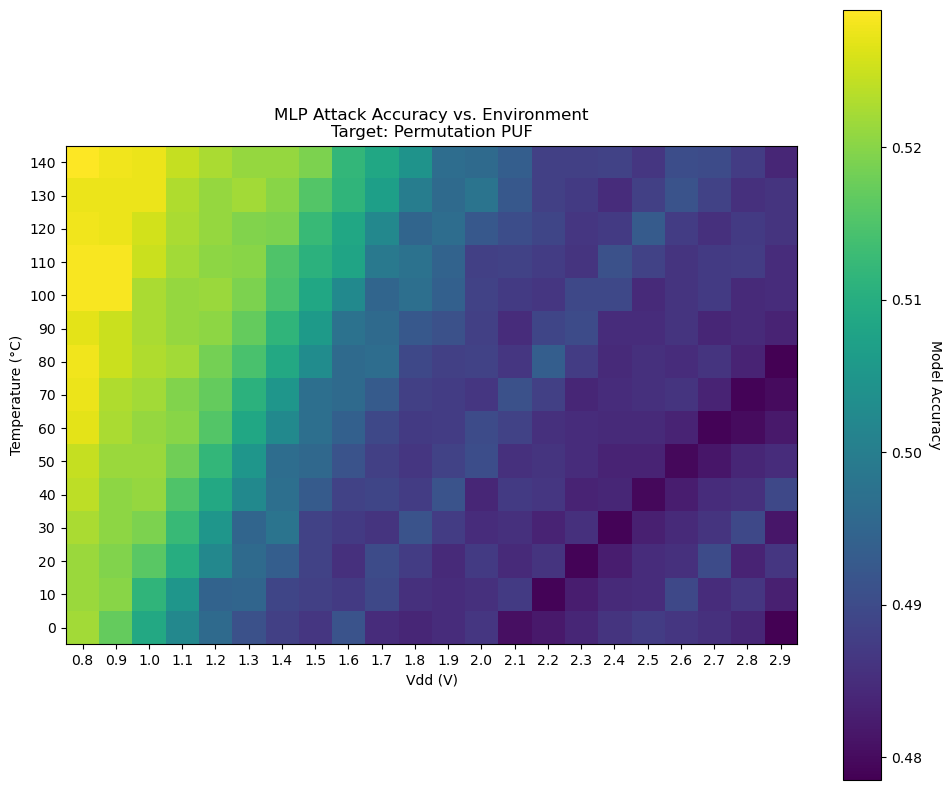

In [19]:
from pypuf.simulation import PermutationPUF
from pypuf.io import ChallengeResponseSet
from pypuf.attack import MLPAttack2021
from pypuf.metrics import similarity

# 1. Setup Data Generation at Nominal Conditions
# Permutation PUFs utilize k-length blocks to shuffle bit mappings
p_nom = PermutationPUF(n=n_bits, seed=puf_seed, temperature=nom_temp, vdd=nom_vdd, k=8)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=n_train, seed=puf_seed)

# 2. Run MLP Attack
# net=[n_bits, n_bits] defines the hidden layers for the neural network
# bs=128 is the standard batch size for gradient-based pypuf attacks
model = MLPAttack2021(
    train_crps, 
    seed=42, 
    net=[n_bits, n_bits], 
    epochs=50, 
    lr=1e-3, 
    bs=128, 
    early_stop=0.01
).fit()

# Ensure the model knows it was trained at nominal conditions for physics evaluation
model.temperature, model.vdd = nom_temp, nom_vdd

# 3. Environmental Sweep Evaluation
acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        # Create target instance with shifted environmental parameters
        p_eval = PermutationPUF(n=n_bits, seed=puf_seed, temperature=t, vdd=v, k=8)
        
        # similarity() compares the fixed MLP model against the shifted device
        # seed=4 internally generates random inputs for verification [cite: 30]
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0]

# 4. Visualize Results
plot_environmental_heatmap(acc_grid, temp_range, vdd_range, "Permutation PUF", "MLP Attack")

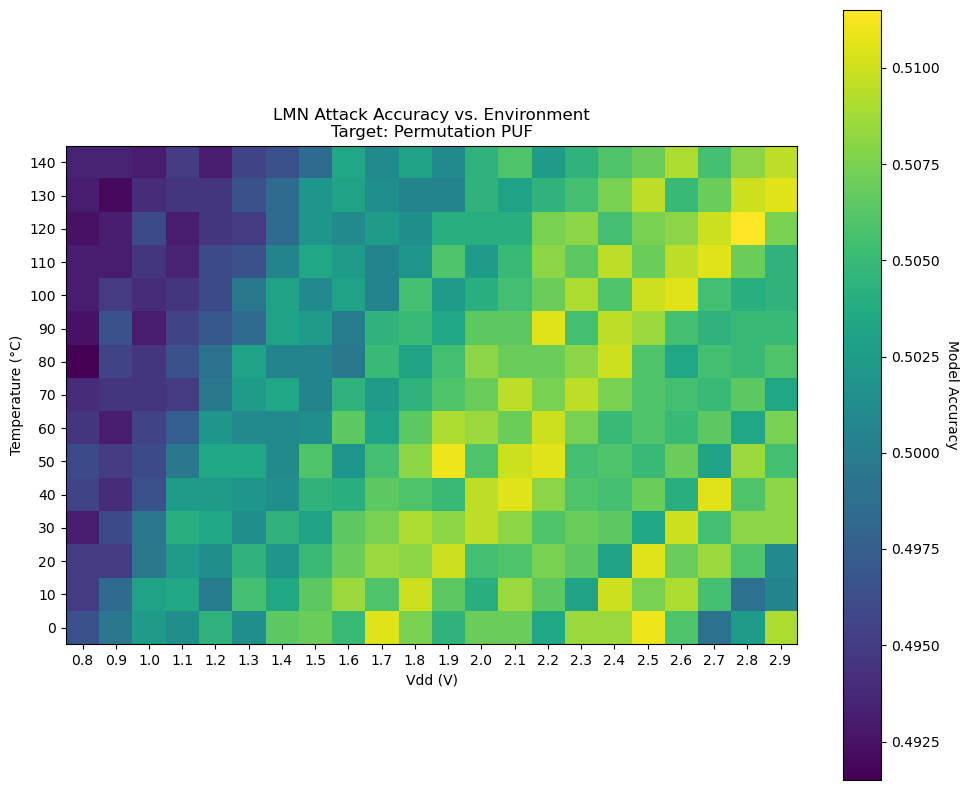

In [20]:
from pypuf.simulation import PermutationPUF
from pypuf.io import ChallengeResponseSet
from pypuf.attack import LMNAttack  # 
from pypuf.metrics import similarity

# 1. Setup Data Generation at Nominal Conditions
p_nom = PermutationPUF(n=n_bits, seed=puf_seed, temperature=nom_temp, vdd=nom_vdd, k=8)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=n_train, seed=puf_seed)

# 2. Run LMN Attack
# Degree 1 approximations are computationally linear and highly effective [cite: 17, 18, 32]
model = LMNAttack(train_crps, deg=1).fit()  # [cite: 22, 23, 32]

# Ensure the model knows it was trained at nominal conditions for physics evaluation
model.temperature, model.vdd = nom_temp, nom_vdd

# 3. Environmental Sweep Evaluation
acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        # Create target instance with shifted environmental parameters
        p_eval = PermutationPUF(n=n_bits, seed=puf_seed, temperature=t, vdd=v, k=8)
        
        # similarity() compares the fixed LMN model against the shifted device 
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0]

# 4. Visualize Results
plot_environmental_heatmap(acc_grid, temp_range, vdd_range, "Permutation PUF", "LMN Attack")

Epoch 1/50
1161/1161 [==============================] - 5s 3ms/step - loss: 0.6871 - accuracy: 0.5584 - val_loss: 0.6911 - val_accuracy: 0.5427
Epoch 2/50
1161/1161 [==============================] - 4s 4ms/step - loss: 0.6837 - accuracy: 0.5645 - val_loss: 0.6870 - val_accuracy: 0.5597
Epoch 3/50
1161/1161 [==============================] - 4s 4ms/step - loss: 0.6601 - accuracy: 0.6105 - val_loss: 0.6507 - val_accuracy: 0.6177
Epoch 4/50
1161/1161 [==============================] - 4s 4ms/step - loss: 0.6231 - accuracy: 0.6517 - val_loss: 0.5991 - val_accuracy: 0.6720
Epoch 5/50
1161/1161 [==============================] - 5s 4ms/step - loss: 0.5616 - accuracy: 0.7093 - val_loss: 0.5470 - val_accuracy: 0.7153
Epoch 6/50
1161/1161 [==============================] - 4s 4ms/step - loss: 0.5214 - accuracy: 0.7396 - val_loss: 0.5296 - val_accuracy: 0.7320
Epoch 7/50
1161/1161 [==============================] - 5s 4ms/step - loss: 0.5081 - accuracy: 0.7445 - val_loss: 0.5209 - val_accuracy:

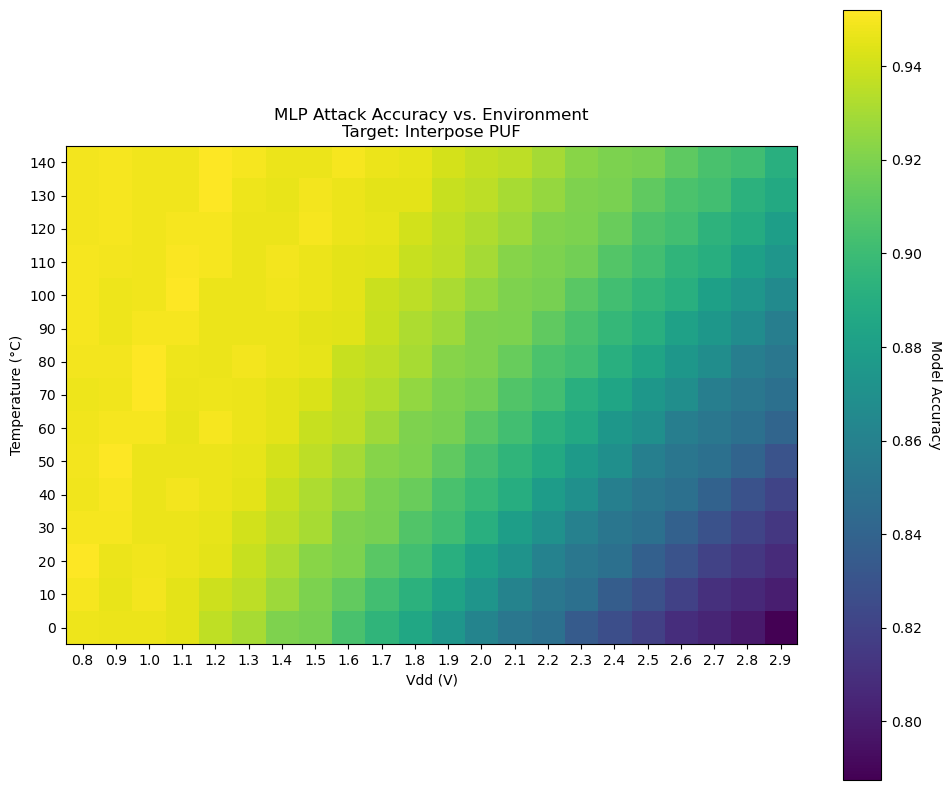

In [21]:
from pypuf.simulation import InterposePUF

# k_up and k_down represent the number of chains in the top and bottom segments
p_nom = InterposePUF(n=n_bits, k_up=2, k_down=2, seed=puf_seed, temperature=nom_temp, vdd=nom_vdd)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=300000, seed=puf_seed) # Requires large N

model = MLPAttack2021(train_crps, 42, [n_bits, n_bits, n_bits], 50, 1e-4, 256, 0.01).fit()
model.temperature, model.vdd = nom_temp, nom_vdd

acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        p_eval = InterposePUF(n=n_bits, k_up=2, k_down=2, seed=puf_seed, temperature=t, vdd=v)
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0]

plot_environmental_heatmap(acc_grid, temp_range, vdd_range, "Interpose PUF", "MLP Attack")